# **Lab 5. Working with Vector Data using GeoPandas**
**GY674 / GY675**

**Today:** Learn how to work with vector data in Python, using Irish Electoral Division boundaries, deprivation data and railway infrastructure to explore geographical patterns of inequality.

### What we'll learn

1. **Read** → Import vector data: points, lines and polygons.
2. **Explore** → Examine spatial features, attributes and coordinate reference systems (CRS).
3. **Merge** → Combine Pobal deprivation data with Electoral Division boundaries using `.merge`
4. **Analyse** → Aggregate Electoral Divisions into counties using `.dissolve()`.
5. **Visualise** → Create maps combining deprivation, railway lines and station points.

### Today's workflow

- **Part 1:** Explore vector data and merge deprivation data to Electoral Divisions.
- **Part 2:** Aggregate Electoral Divisions into counties and map deprivation.
- **Further:** Combine polygons, lines and points on one map.

### How to use this notebook

- 👀 **Demo** – Follow along.
- ✏️ **Your turn** – Practise the code.
- ⭐ **Challenge** – Apply your skills independently.



---
# **Part 1: How does deprivation vary across Ireland at the Electoral Division (ED) level (making our first map)**


# **Step 1. READ**

### Today's datasets

We'll work with two datasets covering Ireland's **Electoral Divisions (EDs)**:

1. **[hp-deprivation-index-scores-2022_lab3.csv](https://github.com/shaunharrigan/maynooth-geo-python/blob/main/data/hp-deprivation-index-scores-2022_lab3.csv)** — a CSV containing deprivation scores for each ED, which we've used before (**Tabular data -> Pandas -> DataFrame**).
2. **[CSO_Electoral_Divisions_National_Statistical_Boundaries_2022.gpkg](https://github.com/shaunharrigan/maynooth-geo-python/releases/tag/datasets-2026)** — a spatial dataset containing the geographical boundaries of EDs (**Vector spatial data (polygons) -> GeoPandas -> GeoDataFrame**).

We'll use **pandas** to read the deprivation data and **GeoPandas** to read the spatial boundaries. Later, we'll join them together to create maps.

### **Really Important to get the set-up right:**

* Download and saveboth datasets above (.csv & .gpkg) in your Google Drive folder
* Import all packages needed
* Connect Colab to Google Drive
* Read the CSV using `pd.read_csv()` and the spatial data using `gpd.read_file()`
  
**Remember:** Your file paths and filenames must match where you saved the data.

In [1]:
# Import packages
import pandas as pd          # Work with tabular data
import geopandas as gpd       # Work with spatial (vector) data
import matplotlib.pyplot as plt  # Create plots and maps

In [2]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Define the data directory
data_dir = "/content/drive/MyDrive/geo_python_labs_2026/data/"

# Define the output directory, e.g. where to save Figures and new datasets
output_dir = "/content/drive/MyDrive/geo_python_labs_2026/outputs/"

# Read the Pobal CSV (update the filename to match your file)
pobal_df = pd.read_csv(data_dir + "hp-deprivation-index-scores-2022_lab3.csv")

# Read Electoral Division boundaries
ed_gdf = gpd.read_file(data_dir + "CSO_Electoral_Divisions_National_Statistical_Boundaries_2022.gpkg")

# **Step 2. EXPLORE**

In [4]:
# Have a look again at the pobal dataset
pobal_df

,COUNTY,AREA,ED_ID_STR,ED_ENGLISH,TOTPOP22,AGEDEP22,LONEPA22,EDLOW_22,EDHIGH22,HLPROF22,...,UNEMPM22,UNEMPF22,OWNOCC22,PRRENT22,LARENT22,PEROOM22,Index22_ED_std_rel_wt,Index22_ED_std_abs_wt,Index22_ED_rel_wt_cat,Index22_ED_rel_wt_lab
0,LIMERICK,LIMERICK CITY,128024,JOHN'S A,747,37.35,68.24,33.96,3.96,4.15,...,36.09,30.56,44.48,4.14,47.24,0.54,-44.92,-41.73,1,Extremely Disadvantaged
1,LIMERICK,LIMERICK CITY,128020,GALVONE B,739,39.11,62.16,33.51,7.77,3.92,...,33.33,21.31,34.21,3.51,58.33,0.66,-33.24,-31.68,1,Extremely Disadvantaged
2,LIMERICK,LIMERICK CITY,128027,KILLEELY A,"1,455.00",36.98,57.50,29.89,10.45,13.61,...,28.88,19.46,50.45,6.51,35.62,0.54,-29.61,-28.02,2,Very Disadvantaged
3,LIMERICK,LIMERICK CITY,128007,BALLYNANTY,"3,030.00",38.48,56.07,29.75,11.22,13.23,...,24.69,22.24,42.55,5.62,47.33,0.54,-28.64,-27.13,2,Very Disadvantaged
4,DUBLIN,DUBLIN CITY,268122,PRIORSWOOD B,"2,794.00",33.89,56.70,29.22,9.20,12.06,...,24.01,18.03,38.93,4.98,51.64,0.68,-28.18,-26.93,2,Very Disadvantaged
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3412,DUBLIN,DUBLIN CITY,268116,PEMBROKE WEST B,"3,214.00",23.68,8.46,1.95,84.83,64.19,...,4.21,5.16,35.12,61.10,1.04,0.49,15.33,12.92,6,Affluent
3413,DUBLIN,DUN LAOGHAIRE/RATHDOWN,267069,DUN LAOGHAIRE-GLENAGEARY,"4,516.00",30.16,12.96,1.68,80.52,69.75,...,4.87,8.30,44.84,46.67,3.29,0.52,15.37,12.90,6,Affluent
3414,DUBLIN,DUBLIN CITY,268148,USHERS A,"5,117.00",12.21,21.30,3.19,78.31,51.30,...,6.30,5.88,11.79,78.54,4.96,0.68,15.73,12.23,6,Affluent
3415,DUBLIN,DUN LAOGHAIRE/RATHDOWN,267055,CLONSKEAGH-MILLTOWN,"2,252.00",31.84,8.96,1.07,83.79,69.40,...,3.63,2.34,69.17,27.97,0.55,0.45,16.23,14.02,6,Affluent


In [5]:
# Look at the type...
print(type(pobal_df))

<class 'pandas.core.frame.DataFrame'>


In [6]:
# Have a look at the data types etc (it's a Pandas DataFrame)
pobal_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3417 entries, 0 to 3416
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   COUNTY                 3417 non-null   object 
 1   AREA                   3417 non-null   object 
 2   ED_ID_STR              3417 non-null   object 
 3   ED_ENGLISH             3417 non-null   object 
 4   TOTPOP22               3417 non-null   object 
 5   AGEDEP22               3417 non-null   float64
 6   LONEPA22               3417 non-null   float64
 7   EDLOW_22               3417 non-null   float64
 8   EDHIGH22               3417 non-null   float64
 9   HLPROF22               3417 non-null   float64
 10  LCLASS22               3417 non-null   float64
 11  UNEMPM22               3417 non-null   float64
 12  UNEMPF22               3417 non-null   float64
 13  OWNOCC22               3417 non-null   float64
 14  PRRENT22               3417 non-null   float64
 15  LARE

In [7]:
# Now let's check out the Electoral Division (ED) vector dataset (it's a GeoDataFrame)
ed_gdf

,ED_GUID,ED_OFFICIAL,ED_ENGLISH,ED_GAEILGE,ED_ID_STR,ED_PART_COUNT,COUNTY_CODE,COUNTY_ENGLISH,COUNTY_GAEILGE,CSO_LEA,geometry
0,06698531-f7f7-4058-a15f-7d455ef0dd94,N,KILLINAGH/TEEBANE,CILL LAIGHNEACH/AN TAOBH BÁN,027058/027085,1,32,CAVAN,An Cabhán,CAVAN-BELTURBET,"MULTIPOLYGON (((605406.79 833829.67, 605387.02..."
1,21a09083-a130-47d2-8690-23338d5ecf18,N,CASTLETOWN (NORTH),CAISLEÁN DHÚN DEALGAN (THUAIDH),147008,1,10,LOUTH,Lú,DUNDALK-CARLINGFORD,"MULTIPOLYGON (((702464.746 810977.299, 702458...."
2,23519126-bd85-4c40-a1e2-26c5d2b7e51c,N,ARIGNA/DRUMKEERAN/KILLARGA,AN AIRGNIGH/DROIM CAORTHAINN/CILL FHEARGA,117029/117007/117054,1,28,LEITRIM,Liatroim,MANORHAMILTON,"MULTIPOLYGON (((595326.354 834376.258, 595275...."
3,268c20e2-7574-4e64-ac7a-9383e368fcb7,N,DERRYLEA/DERRYCUNLAGH,DOIRE LIATH/DOIRE CHUNLAIGH,067081/067084,1,27,GALWAY,Gaillimh,CONAMARA NORTH,"MULTIPOLYGON (((472419.626 753263.753, 472298...."
4,2ae19629-16a1-13a3-e055-000000000001,Y,BALLYADAMS,BAILE ADAIM,107008,1,08,LAOIS,Laois,GRAIGUECULLEN-PORTARLINGTON,"MULTIPOLYGON (((661308.671 694565.273, 661274...."
...,...,...,...,...,...,...,...,...,...,...,...
3415,f26b950c-de46-4c46-b4be-21b2c886958f,N,DUNDALK RURAL (SOUTH),DÚN DEALGAN TUATH (THEAS),147019,1,10,LOUTH,Lú,DUNDALK SOUTH,"MULTIPOLYGON (((708227.605 807807.032, 708231...."
3416,f2b35649-c96c-4cf5-b8ab-60770f0291a9,N,MASTERGEEHY/CANUIG,MÁISTIR GAOITHE/CEANNÚIGH,077037/077133,1,19,KERRY,Ciarraí,KENMARE,"MULTIPOLYGON (((458470.971 575155.842, 458459...."
3417,f91caa0f-0c2d-4ce7-a5b0-7a5ac354cb4f,N,DUNMAKEEVER/BENBRACK/DERRYNANANTA,DÚN MHIC ÍOMHAIR/AN BHINN BHREAC/DOIRE NA NEANTA,027014/027038,1,32,CAVAN,An Cabhán,CAVAN-BELTURBET,"MULTIPOLYGON (((609394.898 829693.959, 609353...."
3418,fbd773f9-3255-4b44-ade1-02facf2621f8,N,MOHERNAGH/DUNMOYLAN WEST,MOTHARNACH/DÚN MAOILÍN THIAR,127110/127065,1,21,LIMERICK,Luimneach,ADARE-RATHKEALE,"MULTIPOLYGON (((521057.895 647238.088, 521052...."


In [8]:
# Check out .info()
ed_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3420 entries, 0 to 3419
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   ED_GUID         3420 non-null   object  
 1   ED_OFFICIAL     3420 non-null   object  
 2   ED_ENGLISH      3420 non-null   object  
 3   ED_GAEILGE      3420 non-null   object  
 4   ED_ID_STR       3420 non-null   object  
 5   ED_PART_COUNT   3420 non-null   int16   
 6   COUNTY_CODE     3420 non-null   object  
 7   COUNTY_ENGLISH  3420 non-null   object  
 8   COUNTY_GAEILGE  3420 non-null   object  
 9   CSO_LEA         3420 non-null   object  
 10  geometry        3420 non-null   geometry
dtypes: geometry(1), int16(1), object(9)
memory usage: 274.0+ KB


In [9]:
# Check the dataset type...
print(type(ed_gdf))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [10]:
# Chek number of rows and columns
print("Shape:", ed_gdf.shape)

Shape: (3420, 11)


In [11]:
# Check column names
print("Columns:", ed_gdf.columns)

Columns: Index(['ED_GUID', 'ED_OFFICIAL', 'ED_ENGLISH', 'ED_GAEILGE', 'ED_ID_STR',
       'ED_PART_COUNT', 'COUNTY_CODE', 'COUNTY_ENGLISH', 'COUNTY_GAEILGE',
       'CSO_LEA', 'geometry'],
      dtype='object')


In [12]:
# Check the spatial coordinate reference system (CRS)
# Coordinate reference system
print("Coordinate Reference System (CRS) is:", ed_gdf.crs)

Coordinate Reference System (CRS) is: EPSG:2157


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

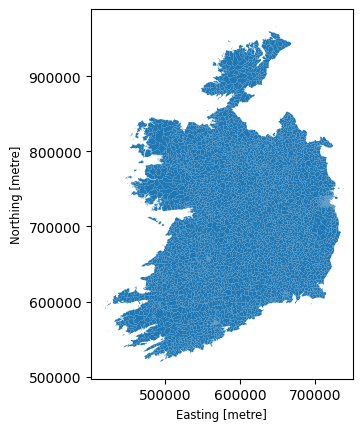

In [13]:
# Quick map
ed_gdf.plot()

## Check your understanding

* Have you seen that the Pobal .csv data is read as a Pandas DataFrame?
* Have you seen that the ED vector data (.gpkg) is read as a GeoPandas GeoDataFrame?

# **Step 3. PREPARE**

Our next task is to **merge two datasets** so we can analyse and map deprivation across Ireland's Electoral Divisions (EDs).

We'll first use a small example to introduce pandas `.merge()`, which allows us to combine datasets using a common identifier.

We'll then apply this to our real datasets:

- **ED boundaries (GeoDataFrame):** Contains the geographical boundaries and attributes of each Electoral Division.
- **Pobal deprivation data (DataFrame):** Contains deprivation information for each Electoral Division.

**Our goal:** Add the Pobal deprivation data to the attribute table of our ED boundaries, so we can map and explore geographical patterns of deprivation.


### 👀 Demo | Merging datasets with `.merge()`

We can use pandas `.merge()` to combine two datasets using a **common column**.

There are four main types of merges, depending on which records we want to keep:

- **Left:** Keep all rows from the first dataset.
- **Right:** Keep all rows from the second dataset.
- **Inner:** Keep only rows with matching values in both datasets.
- **Outer:** Keep all rows from both datasets.

<img src="https://raw.githubusercontent.com/shaunharrigan/maynooth-geo-python/main/images/pandas_merge_types.png" width="750">

Let's try a **left merge** and an **inner merge** using two small datasets.

We have two simple pandas DataFrames:

- **Dataset 1:** ED information (ID, name and county).
- **Dataset 2:** Deprivation scores for each ED.

Both datasets contain a common column, `ED_ID_STR`, which we'll use to merge them.

In [14]:
# Dataset 1: ED information
eds = pd.DataFrame({
    "ED_ID_STR": ["001", "002", "003"],
    "ED_Name": ["North", "South", "West"],
    "County": ["Donegal", "Mayo", "Galway"]
})

# Dataset 2: Deprivation scores
deprivation = pd.DataFrame({
    "ED_ID_STR": ["001", "002", "004"],
    "Deprivation": [-5.2, 1.3, 0.8]
})

# Display both datasets
display(eds, deprivation)

,ED_ID_STR,ED_Name,County
0,001,North,Donegal
1,002,South,Mayo
2,003,West,Galway


,ED_ID_STR,Deprivation
0,001,-5.2
1,002,1.3
2,004,0.8


In [15]:
# Inner join: keep only matching EDs
merged_inner = eds.merge(deprivation, on="ED_ID_STR", how="inner")

merged_inner

,ED_ID_STR,ED_Name,County,Deprivation
0,001,North,Donegal,-5.2
1,002,South,Mayo,1.3


In [16]:
# Inner join: keep only matching EDs

# Try a left join, create a new left join on eds with deprivation on="ED_ID_STR" called 'merged_left'
merged_left = eds.merge(deprivation, on="ED_ID_STR", how="left")

merged_left


,ED_ID_STR,ED_Name,County,Deprivation
0,001,North,Donegal,-5.2
1,002,South,Mayo,1.3
2,003,West,Galway,NaN


In [17]:
# Now check for any missing values (i.e. NA's or NaN's)
merged_left.isna().sum()

,0
ED_ID_STR,0
ED_Name,0
County,0
Deprivation,1



### 👀 Demo | Merging our ED boundaries with Pobal deprivation data

Now let's apply `.merge()` to our real datasets.

We'll use a **left merge** to add the Pobal deprivation data (`pobal_df`) to our ED boundaries (`ed_gdf`), matching records using `ED_ID_STR`.

Our goal is to **retain all ED boundaries** and add their corresponding deprivation information, so we can map deprivation across Ireland.


In [18]:
# Left merge: keep all ED boundaries within 'ed_gdf'
merged_ed_gdf = ed_gdf.merge(pobal_df, on="ED_ID_STR", how="left")

merged_ed_gdf

,ED_GUID,ED_OFFICIAL,ED_ENGLISH_x,ED_GAEILGE,ED_ID_STR,ED_PART_COUNT,COUNTY_CODE,COUNTY_ENGLISH,COUNTY_GAEILGE,CSO_LEA,...,UNEMPM22,UNEMPF22,OWNOCC22,PRRENT22,LARENT22,PEROOM22,Index22_ED_std_rel_wt,Index22_ED_std_abs_wt,Index22_ED_rel_wt_cat,Index22_ED_rel_wt_lab
0,06698531-f7f7-4058-a15f-7d455ef0dd94,N,KILLINAGH/TEEBANE,CILL LAIGHNEACH/AN TAOBH BÁN,027058/027085,1,32,CAVAN,An Cabhán,CAVAN-BELTURBET,...,17.07,13.79,77.27,9.09,6.82,0.44,-12.42,-12.12,3.0,Disadvantaged
1,21a09083-a130-47d2-8690-23338d5ecf18,N,CASTLETOWN (NORTH),CAISLEÁN DHÚN DEALGAN (THUAIDH),147008,1,10,LOUTH,Lú,DUNDALK-CARLINGFORD,...,16.63,14.18,63.12,11.26,18.06,0.50,-10.76,-10.98,3.0,Disadvantaged
2,23519126-bd85-4c40-a1e2-26c5d2b7e51c,N,ARIGNA/DRUMKEERAN/KILLARGA,AN AIRGNIGH/DROIM CAORTHAINN/CILL FHEARGA,117029/117007/117054,1,28,LEITRIM,Liatroim,MANORHAMILTON,...,10.79,11.29,66.41,7.03,18.36,0.43,-5.09,-6.03,4.0,Marginally Below Average
3,268c20e2-7574-4e64-ac7a-9383e368fcb7,N,DERRYLEA/DERRYCUNLAGH,DOIRE LIATH/DOIRE CHUNLAIGH,067081/067084,1,27,GALWAY,Gaillimh,CONAMARA NORTH,...,11.24,5.63,82.40,12.80,1.60,0.43,-3.32,-4.12,4.0,Marginally Below Average
4,2ae19629-16a1-13a3-e055-000000000001,Y,BALLYADAMS,BAILE ADAIM,107008,1,08,LAOIS,Laois,GRAIGUECULLEN-PORTARLINGTON,...,5.41,2.17,90.23,3.01,1.50,0.48,5.23,3.65,5.0,Marginally Above Average
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,f26b950c-de46-4c46-b4be-21b2c886958f,N,DUNDALK RURAL (SOUTH),DÚN DEALGAN TUATH (THEAS),147019,1,10,LOUTH,Lú,DUNDALK SOUTH,...,15.96,14.88,57.16,19.03,18.53,0.52,-7.59,-8.37,4.0,Marginally Below Average
3416,f2b35649-c96c-4cf5-b8ab-60770f0291a9,N,MASTERGEEHY/CANUIG,MÁISTIR GAOITHE/CEANNÚIGH,077037/077133,1,19,KERRY,Ciarraí,KENMARE,...,3.51,6.52,89.41,4.71,4.71,0.41,-3.43,-3.65,4.0,Marginally Below Average
3417,f91caa0f-0c2d-4ce7-a5b0-7a5ac354cb4f,N,DUNMAKEEVER/BENBRACK/DERRYNANANTA,DÚN MHIC ÍOMHAIR/AN BHINN BHREAC/DOIRE NA NEANTA,027014/027038,1,32,CAVAN,An Cabhán,CAVAN-BELTURBET,...,1.82,11.90,89.77,3.41,4.55,0.41,-6.39,-7.11,4.0,Marginally Below Average
3418,fbd773f9-3255-4b44-ade1-02facf2621f8,N,MOHERNAGH/DUNMOYLAN WEST,MOTHARNACH/DÚN MAOILÍN THIAR,127110/127065,1,21,LIMERICK,Luimneach,ADARE-RATHKEALE,...,3.70,2.38,94.52,2.74,0.00,0.42,2.13,0.34,5.0,Marginally Above Average


In [19]:
# Check that there's not mssing values to ensure the 'merge' worked.
merged_ed_gdf.isna().sum()

,0
ED_GUID,0
ED_OFFICIAL,0
ED_ENGLISH_x,0
ED_GAEILGE,0
ED_ID_STR,0
ED_PART_COUNT,0
COUNTY_CODE,0
COUNTY_ENGLISH,0
COUNTY_GAEILGE,0
CSO_LEA,0


### 🔧 Fixing our merge | Why are values missing?

Our merge retained all ED boundaries, but around 1,400 EDs have missing deprivation scores. Why?

The problem is with our **ED identifiers (`ED_ID_STR`)**. These identifiers should contain **six digits**, but some have lost their leading zeros in the original Pobal CSV.

For example, `048039` appears as `48039`, meaning it no longer matches the identifier in our ED boundaries.

We can fix this using **zero-padding**: adding zeros to the beginning of a string until it reaches the required length.

Pandas provides a simple method for this: [`.str.zfill()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.zfill.html).

Let's reload the Pobal data, pad the identifiers to six characters, and try our merge again.

In [20]:
# Reload the original Pobal data
pobal_df = pd.read_csv(data_dir + "hp-deprivation-index-scores-2022_lab3.csv")

# Create a copy and pad ED identifiers with leading zeros
pobal_df_fixed = pobal_df.copy()
pobal_df_fixed["ED_ID_STR"] = pobal_df_fixed["ED_ID_STR"].str.zfill(6)

In [21]:
# Now check ED ID's have 6 characters with zeros at front for those less than 6
pobal_df_fixed["ED_ID_STR"][0:40]

,ED_ID_STR
0,128024
1,128020
2,128027
3,128007
4,268122
5,128023
6,128031
7,228021
8,267141
9,128032


In [22]:
# Repeat the left merge using the corrected Pobal data
merged_ed_gdf_fixed = ed_gdf.merge(pobal_df_fixed, on="ED_ID_STR", how="left")

In [23]:
# Check that there's now no missing rows...
merged_ed_gdf_fixed.isna().sum()

,0
ED_GUID,0
ED_OFFICIAL,0
ED_ENGLISH_x,0
ED_GAEILGE,0
ED_ID_STR,0
ED_PART_COUNT,0
COUNTY_CODE,0
COUNTY_ENGLISH,0
COUNTY_GAEILGE,0
CSO_LEA,0


### Selecting columns for our analysis

Our merged GeoDataFrame contains many columns that we don't need. Let's **select only the relevant columns** to create a simpler GeoDataFrame for our analysis and mapping.

We'll keep the following four columns:

| Column | Purpose |
|---|---|
| `ED_ENGLISH_x` | Identify individual Electoral Divisions |
| `COUNTY` | Identify Counties |
| `Index22_ED_std_rel_wt` | Analyse deprivation scores |
| `geometry` | Store the geographical shapes needed for mapping |

We'll save these as a new GeoDataFrame, keeping our original merged dataset unchanged.


In [24]:
# Select only the columns needed for our analysis
ed_deprivation_gdf = merged_ed_gdf_fixed[
    ["ED_ENGLISH_x", "COUNTY", "Index22_ED_std_rel_wt", "geometry"]
].copy()

# Display our prepared GeoDataFrame
ed_deprivation_gdf.head()

,ED_ENGLISH_x,COUNTY,Index22_ED_std_rel_wt,geometry
0,KILLINAGH/TEEBANE,CAVAN,-12.42,"MULTIPOLYGON (((605406.79 833829.67, 605387.02..."
1,CASTLETOWN (NORTH),LOUTH,-10.76,"MULTIPOLYGON (((702464.746 810977.299, 702458...."
2,ARIGNA/DRUMKEERAN/KILLARGA,LEITRIM,-5.09,"MULTIPOLYGON (((595326.354 834376.258, 595275...."
3,DERRYLEA/DERRYCUNLAGH,GALWAY,-3.32,"MULTIPOLYGON (((472419.626 753263.753, 472298...."
4,BALLYADAMS,LAOIS,5.23,"MULTIPOLYGON (((661308.671 694565.273, 661274...."


In [25]:
# Rename columns for clarity
ed_deprivation_gdf = ed_deprivation_gdf.rename(columns={
    "ED_ENGLISH_x": "ED",
    "Index22_ED_std_rel_wt": "Deprivation_score"
})

ed_deprivation_gdf.head()

,ED,COUNTY,Deprivation_score,geometry
0,KILLINAGH/TEEBANE,CAVAN,-12.42,"MULTIPOLYGON (((605406.79 833829.67, 605387.02..."
1,CASTLETOWN (NORTH),LOUTH,-10.76,"MULTIPOLYGON (((702464.746 810977.299, 702458...."
2,ARIGNA/DRUMKEERAN/KILLARGA,LEITRIM,-5.09,"MULTIPOLYGON (((595326.354 834376.258, 595275...."
3,DERRYLEA/DERRYCUNLAGH,GALWAY,-3.32,"MULTIPOLYGON (((472419.626 753263.753, 472298...."
4,BALLYADAMS,LAOIS,5.23,"MULTIPOLYGON (((661308.671 694565.273, 661274...."


**CHECK POINT BEFORE MOVING TO STEP 4 and 5**

Let's reset the 'Runtime' and check we have everthing correct:

*  **RESTART THE RUNTIME** by clicking on **Runtime** on top left menu **->** **Restart session**
* **Run all cells in order again cleanly before** this cell. To do this, make sure you select this cell -> click **Runtime** from menu **-> Run before**

---



In [26]:
# Check our merged dataset is ready for analysis
print("Number of ED polygons:", len(ed_deprivation_gdf))
print("Missing deprivation scores:",
      ed_deprivation_gdf["Deprivation_score"].isna().sum())

Number of ED polygons: 3420
Missing deprivation scores: 0


# **Step 4. ANALYSE**

Now that we've successfully merged our datasets, we can start exploring **deprivation across Ireland's Electoral Divisions (EDs)**.

Before creating a map, let's examine the deprivation scores using some familiar pandas methods.

We'll:

1. **Summarise** the deprivation scores using `.describe()`.
2. **Explore** their distribution using a histogram.
3. **Identify** the EDs with the highest and lowest deprivation scores.

This will help us understand the data before we visualise its geographical patterns.

**Key question:** How much does deprivation vary between Electoral Divisions in Ireland?

In [27]:
# Summary statistics for ED deprivation scores
ed_deprivation_gdf["Deprivation_score"].describe()

,Deprivation_score
count,3420.000000
mean,-0.517474
std,6.460069
min,-44.920000
25%,-4.320000
50%,-0.125000
75%,3.802500
max,17.500000


<Axes: >

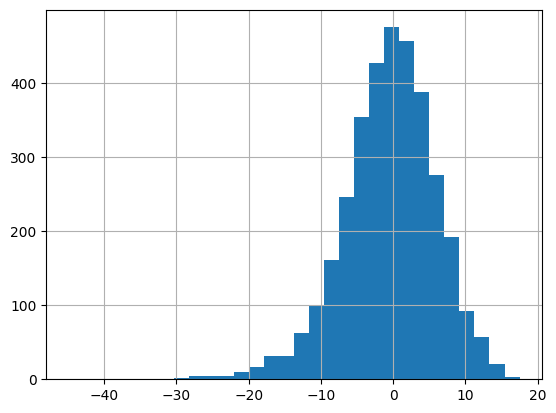

In [28]:
# Plot a histogram of ED deprivation scores
ed_deprivation_gdf["Deprivation_score"].hist(bins=30)

In [29]:
# Most deprived and most affluent EDs
ed_deprivation_gdf.sort_values("Deprivation_score")

,ED,COUNTY,Deprivation_score,geometry
332,JOHN'S A,LIMERICK,-44.92,"MULTIPOLYGON (((557739.115 658824.942, 557717...."
322,GALVONE B,LIMERICK,-33.24,"MULTIPOLYGON (((559679.711 654964.54, 559662.9..."
335,KILLEELY A,LIMERICK,-29.61,"MULTIPOLYGON (((557320.496 659491.214, 557282...."
309,BALLYNANTY,LIMERICK,-28.64,"MULTIPOLYGON (((557006.275 659775.001, 557007...."
1799,PRIORSWOOD B,DUBLIN,-28.18,"MULTIPOLYGON (((719837.882 741178.941, 719835...."
...,...,...,...,...
1783,PEMBROKE WEST B,DUBLIN,15.33,"MULTIPOLYGON (((717987.324 732771.014, 717988...."
1655,DUN LAOGHAIRE-GLENAGEARY,DUBLIN,15.37,"MULTIPOLYGON (((723902.551 728080.52, 723881.5..."
1838,USHERS A,DUBLIN,15.73,"MULTIPOLYGON (((713529.955 734313.935, 713526...."
1620,CLONSKEAGH-MILLTOWN,DUBLIN,16.23,"MULTIPOLYGON (((717345.825 730671.067, 717329...."


# **Step 5. VISUALISE**

Now let's create our first **choropleth map** — a map where geographical areas are coloured according to a data value.

We'll map deprivation scores across Ireland's Electoral Divisions (EDs) using GeoPandas `.plot()`.

But making a map is only the beginning. We'll progressively improve its design by considering:

1. **Colour:** Which colours best communicate deprivation and affluence?
2. **Scale:** How should we represent negative and positive scores?
3. **Presentation:** How can we make our map clear, informative and visually appealing?

**Key question:** How can thoughtful map design help us communicate geographical patterns more effectively?


**Map 1 — Our first choropleth map**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

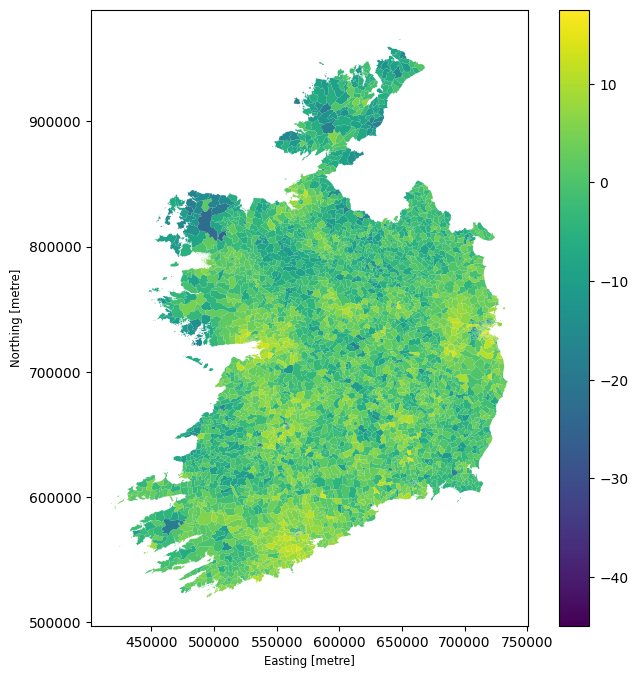

In [30]:
# Our first deprivation map
ed_deprivation_gdf.plot(
    column="Deprivation_score",
    legend=True,
    figsize=(8, 8)
)

**Choosing a colour palette**

Good maps use colours that help communicate the data. Let's explore **sequential** and **diverging** colour palettes, and how `cmap`, `vmin` and `vmax` control their appearance.

<img src="https://raw.githubusercontent.com/shaunharrigan/maynooth-geo-python/main/images/quick_colormaps_cheat_sheet.png" width="900">

**For our deprivation map:** Why is a diverging colour palette centred on zero more appropriate?

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

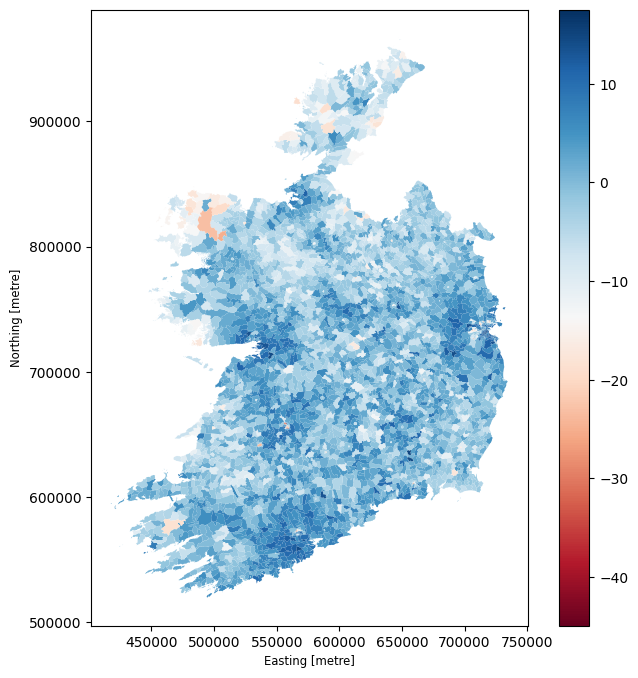

In [31]:
# Improve the colour palette
ed_deprivation_gdf.plot(
    column="Deprivation_score",
    cmap="RdBu",
    legend=True,
    figsize=(8, 8)
)

**Need to set sensible vmin and vmax...**

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

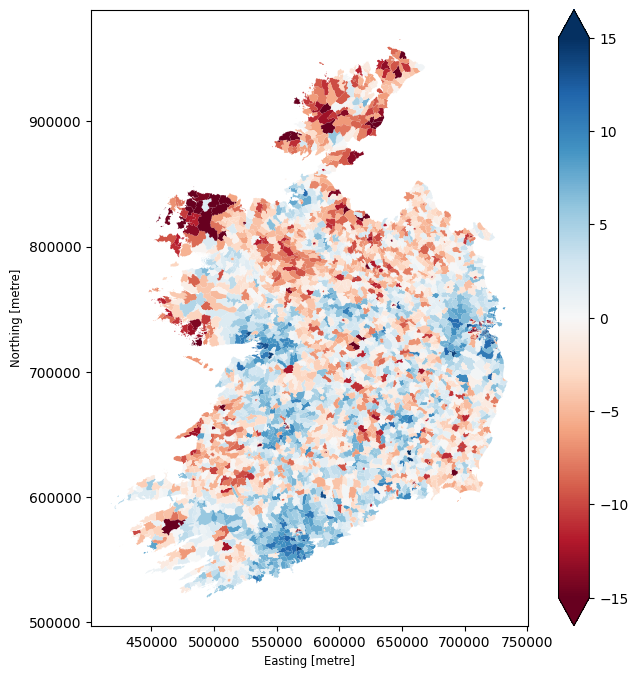

In [32]:
# Map deprivation scores with a colour scale from -15 to +15
ed_deprivation_gdf.plot(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-15,
    vmax=15,
    legend=True,
    figsize=(8, 8)
)

### **Now make a few aesthtic tweaks and save our map to our Google Drive as a .png**

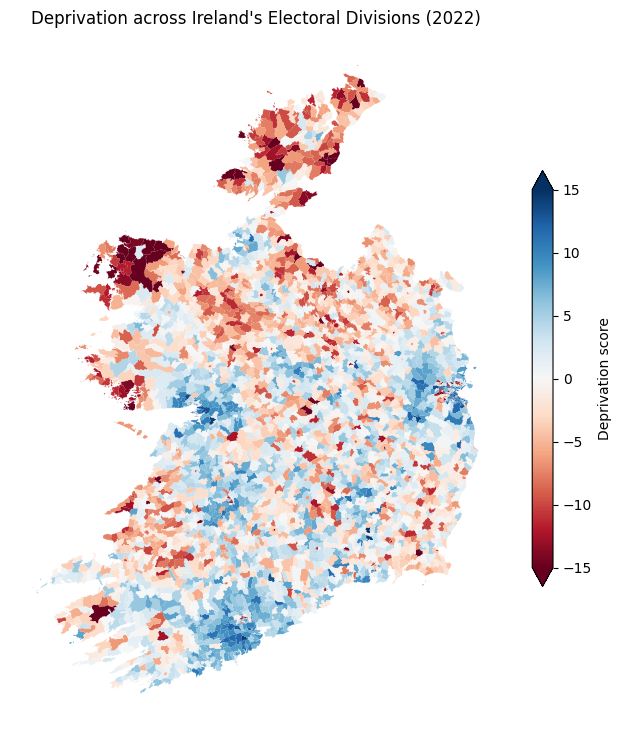

In [33]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(8, 9))

# Map ED deprivation scores
ed_deprivation_gdf.plot(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-15,
    vmax=15,
    legend=True,
    legend_kwds={"label": "Deprivation score", "shrink": 0.6},
    ax=ax
)

# Improve map presentation
ax.set_title("Deprivation across Ireland's Electoral Divisions (2022)")
ax.set_axis_off()

# Save the map_
fig.savefig(output_dir + "ireland_ed_deprivation.png", dpi=300, bbox_inches="tight")

plt.show()

---

# **Part 2: How does deprivation vary across Ireland at the County level?**

We've mapped deprivation across Electoral Divisions (EDs). But what if we want to explore deprivation at a **larger geographical scale**?

GeoPandas `.dissolve()` combines smaller polygons into larger areas, while allowing us to summarise their data (e.g. calculate a mean).

<img src="https://raw.githubusercontent.com/shaunharrigan/maynooth-geo-python/main/images/geopandas_dissolve.png" width="800">

We'll **dissolve EDs into Counties**, calculate their mean deprivation scores, and create a new map.

**Key question:** How do deprivation patterns change when we move from EDs to Counties?


### Dissolving EDs into Counties

We'll use GeoPandas `.dissolve()` to combine ED polygons into larger County areas.

- **`by="COUNTY"`** groups EDs by County and merges their geometries.
- **`aggfunc={"Deprivation_score": "mean"}`** specifies which variable to aggregate and how — calculating the mean deprivation score for each County.

This is similar to pandas `.groupby()`, but also combines the geographical shapes.

**Further reading:** [GeoPandas documentation — Dissolving geometries](https://geopandas.org/en/stable/docs/user_guide/aggregation_with_dissolve.html)


In [34]:
# Have a look at the ed deprivation by ED GeoDataFrame data again
ed_deprivation_gdf

,ED,COUNTY,Deprivation_score,geometry
0,KILLINAGH/TEEBANE,CAVAN,-12.42,"MULTIPOLYGON (((605406.79 833829.67, 605387.02..."
1,CASTLETOWN (NORTH),LOUTH,-10.76,"MULTIPOLYGON (((702464.746 810977.299, 702458...."
2,ARIGNA/DRUMKEERAN/KILLARGA,LEITRIM,-5.09,"MULTIPOLYGON (((595326.354 834376.258, 595275...."
3,DERRYLEA/DERRYCUNLAGH,GALWAY,-3.32,"MULTIPOLYGON (((472419.626 753263.753, 472298...."
4,BALLYADAMS,LAOIS,5.23,"MULTIPOLYGON (((661308.671 694565.273, 661274...."
...,...,...,...,...
3415,DUNDALK RURAL (SOUTH),LOUTH,-7.59,"MULTIPOLYGON (((708227.605 807807.032, 708231...."
3416,MASTERGEEHY/CANUIG,KERRY,-3.43,"MULTIPOLYGON (((458470.971 575155.842, 458459...."
3417,DUNMAKEEVER/BENBRACK/DERRYNANANTA,CAVAN,-6.39,"MULTIPOLYGON (((609394.898 829693.959, 609353...."
3418,MOHERNAGH/DUNMOYLAN WEST,LIMERICK,2.13,"MULTIPOLYGON (((521057.895 647238.088, 521052...."


In [35]:
### THIS CAN TAKE A MINUTE OR SO TO RUN (a lot of calculations) ###

# Dissolve EDs into Counties and calculate mean deprivation
mean_depriv_county = ed_deprivation_gdf.dissolve(
    by="COUNTY",
    aggfunc={"Deprivation_score": "mean"}
)

mean_depriv_county

,geometry,Deprivation_score
COUNTY,,
CARLOW,"POLYGON ((672855.406 637815.896, 672817.862 63...",-0.318333
CAVAN,"POLYGON ((632965.606 789959.751, 632957.902 78...",-4.017416
CLARE,"MULTIPOLYGON (((468631.836 647259.465, 468634....",0.170596
CORK,"MULTIPOLYGON (((479107.63 524480.426, 479101.9...",2.392482
DONEGAL,"MULTIPOLYGON (((564761.273 872395.917, 564794....",-6.235235
DUBLIN,"MULTIPOLYGON (((708395.504 719600, 708363.411 ...",2.170280
GALWAY,"MULTIPOLYGON (((452705.889 740745.177, 452708....",0.630855
KERRY,"MULTIPOLYGON (((444874.068 556217.9, 444869.72...",-1.514817
KILDARE,"POLYGON ((672552.555 682210.206, 672538.576 68...",1.448090


In [36]:
# Sort counties from low to high, like we did in Lab 3
mean_depriv_county["Deprivation_score"].sort_values()

,Deprivation_score
COUNTY,
DONEGAL,-6.235235
CAVAN,-4.017416
LONGFORD,-4.002963
MAYO,-4.000728
LEITRIM,-3.347361
MONAGHAN,-2.668857
WEXFORD,-2.305645
LOUTH,-2.224222
LIMERICK,-1.800930


## **Now, let map the mean deprivation at county level**

**Explore:** [Matplotlib colormap gallery](https://matplotlib.org/stable/gallery/color/colormap_reference.html) — try changing `cmap="RdBu"` to `"coolwarm"`, `"BrBG"` or `"viridis"` and see how the map changes.

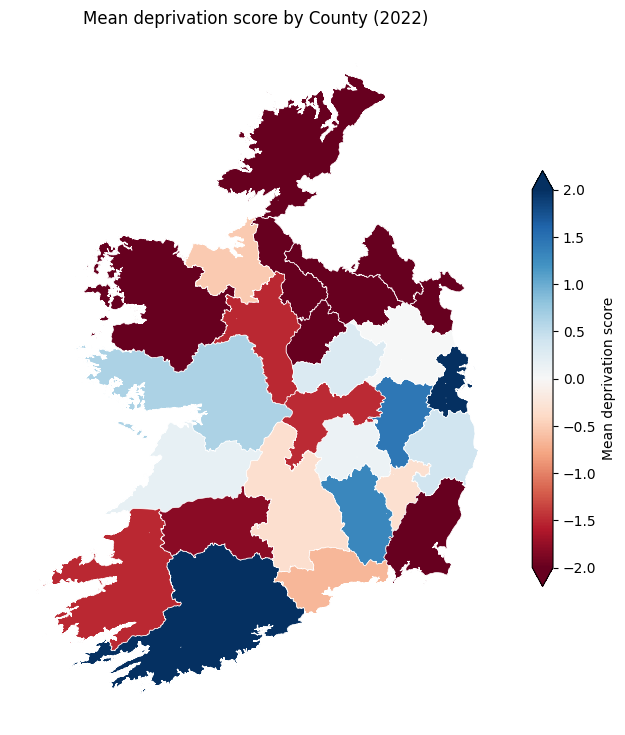

In [37]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(8, 9))

# Map mean County deprivation scores
mean_depriv_county.plot(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-2,
    vmax=2,
    legend=True,
    legend_kwds={"label": "Mean deprivation score", "shrink": 0.6},
    linewidth=0.5,
    edgecolor="white",
    ax=ax
)

# Improve map presentation
ax.set_title("Mean deprivation score by County (2022)")
ax.set_axis_off()

# Save the map
fig.savefig(output_dir + "ireland_county_mean_deprivation.png", dpi=300, bbox_inches="tight")

plt.show()

### **Interactive maps with `.explore()`**

GeoPandas `.explore()` creates **interactive maps** that allow us to zoom, pan and explore geographical data.

Unlike `.plot()`, which creates static maps, `.explore()` uses Folium to create interactive web maps.

Try changing the colourmap (`cmap`) to explore different options.

📖 **Further reading:** [GeoPandas documentation — Interactive mapping](https://geopandas.org/en/stable/docs/user_guide/interactive_mapping.html)


In [38]:
# Interactive County deprivation map (can take 30secs to a minute to run)
mean_depriv_county.explore(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-2,
    vmax=2,
    tiles=None
)

Output hidden; open in https://colab.research.google.com to view.

# **Further & Recomended homework: Combine polygons, lines and points on one map**


## **Average county deprivation and national rail infrastructure**

We will combine **polygons, lines and points** to explore geographical patterns in deprivation and transport infrastructure across Ireland.

- **Polygons:** Mean county deprivation scores calculated earlier.
- **Lines:** [Rail Network – National 250k Map of Ireland](https://data.gov.ie/en_GB/dataset/rail-network-national-250k-map-of-ireland), published by **Tailte Éireann**.
- **Points:** Railway stations, also from Tailte Éireann.
- Combine all three datasets in **GeoPandas** to create a single map.

The railway datasets are loaded directly from an online [ArcGIS Feature Service](https://services-eu1.arcgis.com/FH5XCsx8rYXqnjF5/ArcGIS/rest/services), using URLs provided in the code.

### 💡 A note on coordinate reference systems (CRS)

Different spatial datasets may use different **coordinate reference systems (CRS)**, which define how locations are represented on a map.

Before combining datasets, we need to ensure they use the same CRS.

```python
# Check coordinate systems
print(mean_depriv_county.crs)
print(rail_gdf.crs)
print(stations_gdf.crs)

# Convert to match the county boundaries
rail_gdf = rail_gdf.to_crs(mean_depriv_county.crs)
stations_gdf = stations_gdf.to_crs(mean_depriv_county.crs)
```

**Remember:** `.to_crs()` transforms coordinates so that different spatial layers align correctly.

[Further reading: GeoPandas – Managing projections](https://geopandas.org/en/stable/docs/user_guide/projections.html)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

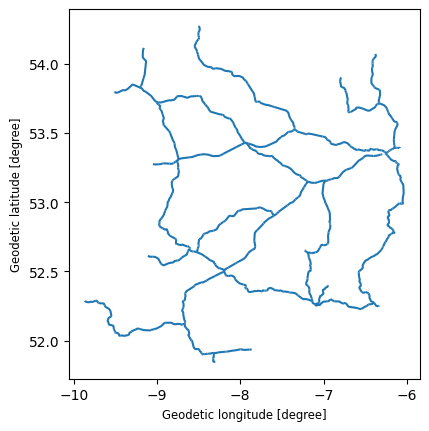

In [39]:
# Read railway network directly from ArcGIS
url = (
    "https://services-eu1.arcgis.com/FH5XCsx8rYXqnjF5/"
    "ArcGIS/rest/services/"
    "Rail_Network___OSi_National_250k_Map_Of_Ireland/"
    "FeatureServer/0/query"
    "?where=1%3D1&outFields=*&outSR=4326&f=geojson"
)

rail_gdf = gpd.read_file(url)

# Explore the data
rail_gdf.plot()

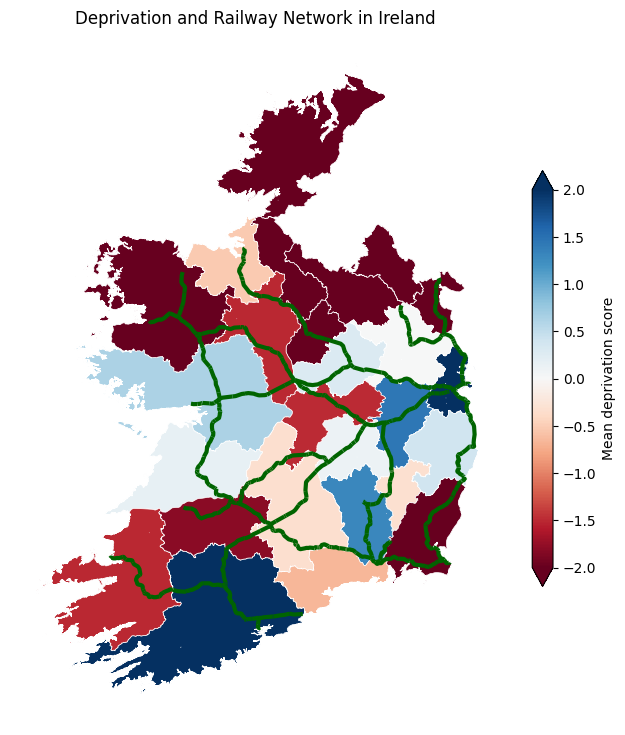

In [40]:
# Add to County deprivation map
# Add railway network to county deprivation map
fig, ax = plt.subplots(figsize=(8, 9))

# County deprivation
mean_depriv_county.plot(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-2,
    vmax=2,
    legend=True,
    legend_kwds={"label": "Mean deprivation score", "shrink": 0.6},
    linewidth=0.5,
    edgecolor="white",
    ax=ax
)

# Railway network
rail_gdf.to_crs(mean_depriv_county.crs).plot(
    ax=ax,
    color="darkgreen",
    linewidth=3
)

ax.set_title("Deprivation and Railway Network in Ireland")
ax.set_axis_off()

plt.show()

## **Combining polygons, lines and points**

- **Polygons:** County boundaries coloured by mean deprivation score.
- **Lines:** National railway network showing transport infrastructure.
- **Points:** [Railway stations](https://services-eu1.arcgis.com/FH5XCsx8rYXqnjF5/ArcGIS/rest/services/Railway_Stations___OSi_National_250k_Map_Of_Ireland/FeatureServer) from Tailte Éireann's ArcGIS API.
- **Combine all three layers** in GeoPandas, ensuring they share the same CRS.
- **Explore:** How does railway infrastructure vary across counties with different levels of deprivation?

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

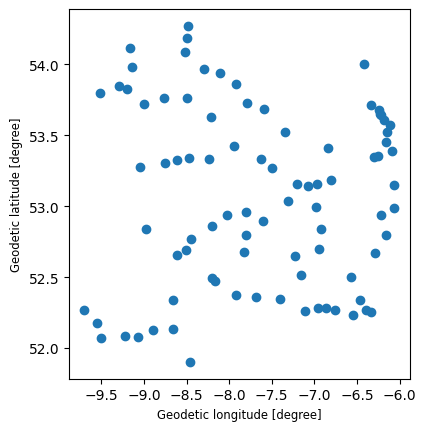

In [41]:
# Read railway stations (point data) directly from ArcGIS API
url = (
    "https://services-eu1.arcgis.com/FH5XCsx8rYXqnjF5/"
    "ArcGIS/rest/services/"
    "Railway_Stations___OSi_National_250k_Map_Of_Ireland/"
    "FeatureServer/0/query"
    "?where=1%3D1&outFields=*&outSR=4326&f=geojson"
)

stations_gdf = gpd.read_file(url)

# Explore the data
stations_gdf.plot()

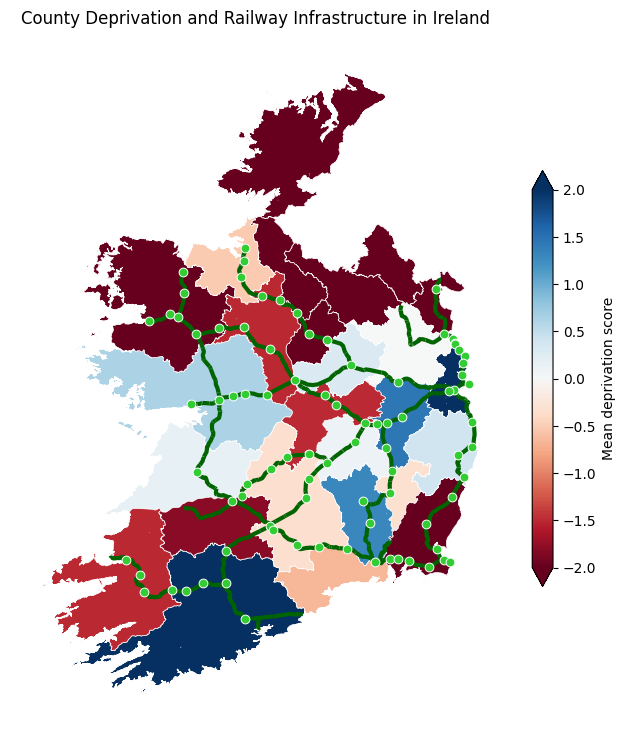

In [42]:
# Combine polygons, lines and points on one map
fig, ax = plt.subplots(figsize=(8, 9))

# 1. Polygons: Mean county deprivation
mean_depriv_county.plot(
    column="Deprivation_score",
    cmap="RdBu",
    vmin=-2,
    vmax=2,
    legend=True,
    legend_kwds={"label": "Mean deprivation score", "shrink": 0.6},
    linewidth=0.5,
    edgecolor="white",
    zorder=1,
    ax=ax
)

# 2. Lines: Railway network
rail_gdf.to_crs(mean_depriv_county.crs).plot(
    ax=ax,
    color="darkgreen",
    linewidth=3,
    zorder=2
)

# 3. Points: Railway stations (on top)
stations_gdf.to_crs(mean_depriv_county.crs).plot(
    ax=ax,
    color="limegreen",
    markersize=40,
    edgecolor="white",
    linewidth=0.7,
    zorder=3
)

ax.set_title("County Deprivation and Railway Infrastructure in Ireland")
ax.set_axis_off()

plt.show()

# **End**